<a href="https://colab.research.google.com/github/jpfortes2/global-innovation-indicators/blob/main/Ecoinfo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
import glob
import pandas as pd

# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Defina o caminho onde a pasta dados_brutos está no seu Drive
# Se você colocou direto na raiz do Drive: '/content/drive/MyDrive/dados_brutos'
# Se colocou dentro de alguma pasta, ajuste o caminho correspondente:
caminho_base = '/content/drive/MyDrive/dados_brutos'

# Verifica se o diretório existe e lista o conteúdo
if os.path.exists(caminho_base):
    print(" Diretório base encontrado com sucesso!")
    print("Conteúdo:", os.listdir(caminho_base))
else:
    print(" Atenção: Caminho não encontrado. Verifique se o nome da pasta no Drive é exatamente 'dados_brutos'.")

Mounted at /content/drive
 Diretório base encontrado com sucesso!
Conteúdo: ['wipo', 'banco_mundial']


In [ ]:
# Definindo as subpastas
pasta_bm = os.path.join(caminho_base, "banco_mundial")
pasta_wipo = os.path.join(caminho_base, "wipo")

# 1. Teste Banco Mundial - Procurando os arquivos CSV de cada indicador
subpastas_bm = ["API_GB", "API_IP", "API_SP", "API_TX"]
print("--- TESTE BANCO MUNDIAL ---")
for sub in subpastas_bm:
    p = os.path.join(pasta_bm, sub)
    arquivos_csv = glob.glob(os.path.join(p, "API_*.csv"))
    if arquivos_csv:
        print(f"[{sub}] Arquivo principal encontrado: {os.path.basename(arquivos_csv[0])}")
    else:
        print(f"[{sub}]  Arquivo não encontrado na pasta {p}")

# 2. Teste WIPO - Procurando o CSV
print("\n--- TESTE WIPO ---")
arquivos_wipo = glob.glob(os.path.join(pasta_wipo, "*.csv"))
if arquivos_wipo:
    print(f"[WIPO] Arquivo encontrado: {os.path.basename(arquivos_wipo[0])}")
else:
    print(" [WIPO] Nenhum arquivo .csv encontrado na pasta wipo.")

--- TESTE BANCO MUNDIAL ---
[API_GB] Arquivo principal encontrado: API_GB.XPD.RSDV.GD.ZS_DS2_en_csv_v2_232.csv
[API_IP] Arquivo principal encontrado: API_IP.PAT.RESD_DS2_en_csv_v2_33231.csv
[API_SP] Arquivo principal encontrado: API_SP.POP.SCIE.RD.P6_DS2_en_csv_v2_37695.csv
[API_TX] Arquivo principal encontrado: API_TX.VAL.TECH.MF.ZS_DS2_en_csv_v2_67.csv

--- TESTE WIPO ---
[WIPO] Arquivo encontrado: countryprofiles_1 - Country profiles_Total count by applicant's origin_1980_2024.csv


In [ ]:
import numpy as np

# 1. Carregar metadados de países do Banco Mundial para filtrar apenas países reais
# (exclui blocos regionais, agregados mundiais e faixas de rendimento)
caminho_meta = glob.glob(os.path.join(pasta_bm, "API_GB", "Metadata_Country_*.csv"))[0]
df_meta = pd.read_csv(caminho_meta)

# Filtra códigos de países com 'Region' preenchida (países soberanos)
codigos_paises_validos = set(df_meta[df_meta['Region'].notna() & (df_meta['Region'] != '')]['Country Code'])

# 2. Dicionário de tradução dos nomes dos países para Português
traducao_paises = {
    "Korea, Rep.": "Coreia do Sul",
    "Korea, Dem. People's Rep.": "Coreia do Norte",
    "United States": "Estados Unidos",
    "United Kingdom": "Reino Unido",
    "Russian Federation": "Rússia",
    "Netherlands": "Países Baixos",
    "Switzerland": "Suíça",
    "Sweden": "Suécia",
    "Germany": "Alemanha",
    "Japan": "Japão",
    "China": "China",
    "France": "França",
    "Italy": "Itália",
    "Spain": "Espanha",
    "Canada": "Canadá",
    "Brazil": "Brasil",
    "India": "Índia",
    "Israel": "Israel",
    "Austria": "Áustria",
    "Belgium": "Bélgica",
    "Finland": "Finlândia",
    "Denmark": "Dinamarca",
    "Norway": "Noruega",
    "Singapore": "Singapura",
    "Iceland": "Islândia",
    "Hong Kong SAR, China": "Hong Kong, China",
    "Hong Kong": "Hong Kong, China",
    "Turkiye": "Turquia",
    "Turkey": "Turquia",
    "Viet Nam": "Vietnã",
    "Vietnam": "Vietnã",
    "Malaysia": "Malásia",
    "Philippines": "Filipinas",
    "Cayman Islands": "Ilhas Caimão",
    "Papua New Guinea": "Papua-Nova Guiné"
}

def traduzir(nome):
    return traducao_paises.get(nome, nome)

print(f"Total de países válidos mapeados: {len(codigos_paises_validos)}")

Total de países válidos mapeados: 217


In [ ]:
# Anos definidos para a pesquisa (Frequência 5)
anos_bm = [2001, 2006, 2011, 2016, 2021]
anos_wipo = [2004, 2009, 2014, 2019, 2024]

# --- FUNÇÃO PARA O BANCO MUNDIAL ---
def processar_banco_mundial(subpasta, anos, ano_base=2021, eh_quantidade=False):
    caminho_csv = glob.glob(os.path.join(pasta_bm, subpasta, "API_*.csv"))[0]
    # O Banco Mundial possui 4 linhas de cabeçalho informativo antes dos dados
    df = pd.read_csv(caminho_csv, skiprows=4)

    # Filtrar apenas países individuais
    df = df[df['Country Code'].isin(codigos_paises_validos)].copy()
    df['Pais'] = df['Country Name'].apply(traduzir)

    colunas_anos = [str(a) for a in anos]
    for c in colunas_anos:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    # Identificar o Top 10 com base no ano_base
    ano_base_str = str(ano_base)
    top10_base = df.dropna(subset=[ano_base_str]).sort_values(by=ano_base_str, ascending=False).head(10)
    top10_paises = top10_base['Pais'].tolist()

    linhas_tabela = []

    if eh_quantidade:
        # Para variáveis de quantidade (ex.: Patentes)
        # Calcula ranking mundial e total mundial ano a ano
        totais_mundiais = {ano: df[str(ano)].sum() for ano in anos}

        # Rankings anuais de todos os países
        rankings_anuais = {}
        for ano in anos:
            df_ano = df[['Pais', str(ano)]].dropna().sort_values(by=str(ano), ascending=False)
            df_ano['rank'] = range(1, len(df_ano) + 1)
            rankings_anuais[ano] = dict(zip(df_ano['Pais'], df_ano['rank']))

        # Montar dados dos países do Top 10
        dados_paises = df[df['Pais'].isin(top10_paises)].copy()

        # Ordenar a lista conforme a posição no ano-base
        dados_paises['ordem_base'] = dados_paises['Pais'].apply(lambda x: top10_paises.index(x))
        dados_paises = dados_paises.sort_values(by='ordem_base')

        resultado_dict = {'País': dados_paises['Pais'].tolist()}

        for ano in anos:
            col_ano = str(ano)
            tot_ano = totais_mundiais[ano]

            # Qtde em milhares inteiros
            qtdes = []
            percs = []
            ranks = []

            for _, row in dados_paises.iterrows():
                p = row['Pais']
                val = row[col_ano]
                if pd.isna(val):
                    qtdes.append("N/D")
                    percs.append("N/D")
                    ranks.append("N/D")
                else:
                    qtdes.append(f"{val/1000:,.0f}".replace(",", "."))
                    percs.append(f"{(val/tot_ano)*100:.1f}".replace(".", ",") if tot_ano > 0 else "0,0")
                    ranks.append(str(rankings_anuais[ano].get(p, "-")))

            resultado_dict[f"{ano}_Qtde"] = qtdes
            resultado_dict[f"{ano}_%"] = percs
            resultado_dict[f"{ano}_Rank"] = ranks

        return pd.DataFrame(resultado_dict), top10_base
    else:
        # Para variáveis de intensidade / rácio (% do PIB, pesquisadores por milhão, etc.)
        rankings_anuais = {}
        for ano in anos:
            df_ano = df[['Pais', str(ano)]].dropna().sort_values(by=str(ano), ascending=False)
            df_ano['rank'] = range(1, len(df_ano) + 1)
            rankings_anuais[ano] = dict(zip(df_ano['Pais'], df_ano['rank']))

        dados_paises = df[df['Pais'].isin(top10_paises)].copy()
        dados_paises['ordem_base'] = dados_paises['Pais'].apply(lambda x: top10_paises.index(x))
        dados_paises = dados_paises.sort_values(by='ordem_base')

        resultado_dict = {'País': dados_paises['Pais'].tolist()}
        for ano in anos:
            col_ano = str(ano)
            valores = []
            ranks = []
            for _, row in dados_paises.iterrows():
                p = row['Pais']
                val = row[col_ano]
                if pd.isna(val):
                    valores.append("N/D")
                    ranks.append("N/D")
                else:
                    valores.append(f"{val:.2f}".replace(".", ","))
                    ranks.append(str(rankings_anuais[ano].get(p, "-")))
            resultado_dict[f"{ano}_Valor"] = valores
            resultado_dict[f"{ano}_Rank"] = ranks

        return pd.DataFrame(resultado_dict), top10_base

print("Funções do Banco Mundial criadas!")

Funções do Banco Mundial criadas!


In [ ]:
# Teste com Gastos em P&D
df_pd, top10_pd = processar_banco_mundial("API_GB", anos_bm, ano_base=2021, eh_quantidade=False)
print("=== TABELA: GASTOS EM P&D (% DO PIB) ===")
display(df_pd)

# Teste com Patentes do Banco Mundial (com Qtde em milhar, % e Rank)
df_pat_bm, top10_pat_bm = processar_banco_mundial("API_IP", anos_bm, ano_base=2021, eh_quantidade=True)
print("\n=== TABELA: PEDIDOS DE PATENTES (BANCO MUNDIAL) ===")
display(df_pat_bm)

=== TABELA: GASTOS EM P&D (% DO PIB) ===


,País,2001_Valor,2001_Rank,2006_Valor,2006_Rank,2011_Valor,2011_Rank,2016_Valor,2016_Rank,2021_Valor,2021_Rank
0,Israel,"4,05",1,"4,01",1,"3,92",1,"4,59",1,"5,76",1
1,Coreia do Sul,"2,20",9,"2,62",6,"3,44",3,"3,79",2,"4,60",2
2,Estados Unidos,"2,64",6,"2,55",7,"2,74",8,"2,84",8,"3,47",3
3,Suécia,"3,87",2,"3,48",2,"3,21",4,"3,26",3,"3,42",4
4,Bélgica,"2,03",11,"1,82",15,"2,16",15,"2,53",10,"3,41",5
5,Japão,"2,92",4,"3,23",4,"3,21",5,"3,11",5,"3,27",6
6,Áustria,"2,00",14,"2,38",10,"2,69",9,"3,13",4,"3,26",7
7,Suíça,N/D,N/D,N/D,N/D,N/D,N/D,N/D,N/D,"3,25",8
8,Alemanha,"2,38",7,"2,43",8,"2,75",7,"2,88",7,"3,08",9
9,Finlândia,"3,19",3,"3,33",3,"3,62",2,"2,75",9,"3,01",10



=== TABELA: PEDIDOS DE PATENTES (BANCO MUNDIAL) ===


,País,2001_Qtde,2001_%,2001_Rank,2006_Qtde,2006_%,2006_Rank,2011_Qtde,2011_%,2011_Rank,2016_Qtde,2016_%,2016_Rank,2021_Qtde,2021_%,2021_Rank
0,China,30,"3,6",5,122,"12,3",4,416,"32,2",1,1.205,"56,6",1,1.427,"62,3",1
1,Estados Unidos,178,"21,2",2,222,"22,2",2,248,"19,2",3,295,"13,9",2,262,"11,5",2
2,Japão,387,"46,3",1,347,"34,8",1,288,"22,3",2,260,"12,2",3,222,"9,7",3
3,Coreia do Sul,74,"8,8",3,125,"12,6",3,138,"10,7",4,163,"7,7",4,186,"8,1",4
4,Alemanha,50,"6,0",4,48,"4,8",5,47,"3,6",5,48,"2,3",5,40,"1,7",5
5,Índia,2,"0,3",15,6,"0,6",11,9,"0,7",10,13,"0,6",10,26,"1,1",6
6,Rússia,25,"3,0",6,28,"2,8",6,26,"2,1",6,27,"1,3",6,20,"0,9",7
7,França,13,"1,6",8,15,"1,5",8,15,"1,1",8,14,"0,7",8,13,"0,6",8
8,Reino Unido,21,"2,6",7,17,"1,8",7,15,"1,2",7,14,"0,7",9,12,"0,5",9
9,Itália,N/D,N/D,N/D,N/D,N/D,N/D,9,"0,7",11,9,"0,4",11,10,"0,4",10


In [ ]:
def processar_wipo(termo_busca, anos, ano_base=2024):
    caminho_csv = glob.glob(os.path.join(pasta_wipo, "*.csv"))[0]

    # 1. Carrega o arquivo garantindo index_col=False para que a primeira coluna (País) não vire índice
    df = pd.read_csv(caminho_csv, skiprows=6, encoding='latin1', index_col=False, on_bad_lines='skip')

    # Remove colunas vazias geradas no final
    df = df.loc[:, ~df.columns.str.contains('^Unnamed')].copy()

    # Coluna 0 é o País por extenso, Coluna 3 é a Estatística
    col_pais = df.columns[0]
    col_stat = df.columns[3]

    # Filtra pelo indicador (Trademark, Patent, Industrial design)
    df = df[df[col_stat].astype(str).str.contains(termo_busca, na=False, case=False)].copy()

    # Padroniza países
    df['Pais'] = df[col_pais].astype(str).str.strip().apply(traduzir)

    # Converte colunas dos anos da pesquisa para numérico
    for a in anos:
        col = str(a)
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        else:
            df[col] = np.nan

    ano_base_str = str(ano_base)

    # 2. Identificar Top 10 com base no ano_base
    top10_base = df.dropna(subset=[ano_base_str]).sort_values(by=ano_base_str, ascending=False).head(10)
    top10_paises = top10_base['Pais'].tolist()

    # Totais mundiais ano a ano na base completa daquele indicador
    totais_mundiais = {ano: df[str(ano)].sum(skipna=True) for ano in anos}

    # Rankings anuais de todos os países
    rankings_anuais = {}
    for ano in anos:
        df_ano = df[['Pais', str(ano)]].dropna().sort_values(by=str(ano), ascending=False)
        df_ano['rank'] = range(1, len(df_ano) + 1)
        rankings_anuais[ano] = dict(zip(df_ano['Pais'], df_ano['rank']))

    dados_paises = df[df['Pais'].isin(top10_paises)].copy()
    dados_paises['ordem_base'] = dados_paises['Pais'].apply(lambda x: top10_paises.index(x))
    dados_paises = dados_paises.sort_values(by='ordem_base')

    resultado_dict = {'País': dados_paises['Pais'].tolist()}
    soma_top10 = {ano: 0.0 for ano in anos}

    for ano in anos:
        col_ano = str(ano)
        tot_ano = totais_mundiais[ano]

        qtdes, percs, ranks = [], [], []

        for _, row in dados_paises.iterrows():
            p = row['Pais']
            val = row[col_ano]
            if pd.isna(val):
                qtdes.append("N/D")
                percs.append("N/D")
                ranks.append("N/D")
            else:
                soma_top10[ano] += val
                qtdes.append(f"{val/1000:,.0f}".replace(",", "."))
                p_val = (val / tot_ano) * 100 if tot_ano > 0 else 0.0
                percs.append(f"{p_val:.1f}".replace(".", ","))
                ranks.append(str(rankings_anuais[ano].get(p, "-")))

        resultado_dict[f"{ano}_Qtde"] = qtdes
        resultado_dict[f"{ano}_%"] = percs
        resultado_dict[f"{ano}_Rank"] = ranks

    df_res = pd.DataFrame(resultado_dict)

    # 3. Linhas de fechamento: Subtotal, Demais Países e Total
    linha_subtotal = {'País': 'Subtotal'}
    linha_demais = {'País': 'Demais Países'}
    linha_total = {'País': 'Total'}

    for ano in anos:
        tot_ano = totais_mundiais[ano]
        sub_top10 = soma_top10[ano]
        demais = max(0.0, tot_ano - sub_top10)

        sub_perc = (sub_top10 / tot_ano) * 100 if tot_ano > 0 else 0.0
        dem_perc = (demais / tot_ano) * 100 if tot_ano > 0 else 0.0

        linha_subtotal[f"{ano}_Qtde"] = f"{sub_top10/1000:,.0f}".replace(",", ".")
        linha_subtotal[f"{ano}_%"] = f"{sub_perc:.1f}".replace(".", ",")
        linha_subtotal[f"{ano}_Rank"] = ""

        linha_demais[f"{ano}_Qtde"] = f"{demais/1000:,.0f}".replace(",", ".")
        linha_demais[f"{ano}_%"] = f"{dem_perc:.1f}".replace(".", ",")
        linha_demais[f"{ano}_Rank"] = ""

        linha_total[f"{ano}_Qtde"] = f"{tot_ano/1000:,.0f}".replace(",", ".")
        linha_total[f"{ano}_%"] = "100,0"
        linha_total[f"{ano}_Rank"] = ""

    df_res = pd.concat([df_res, pd.DataFrame([linha_subtotal, linha_demais, linha_total])], ignore_index=True)
    return df_res

print("Função da WIPO ajustada com sucesso!")

Função da WIPO ajustada com sucesso!


In [ ]:
df_marcas_wipo = processar_wipo("Trademark", anos_wipo, ano_base=2024)
print("=== TABELA: MARCAS REGISTRADAS (WIPO) ===")
display(df_marcas_wipo)

=== TABELA: MARCAS REGISTRADAS (WIPO) ===


,País,2004_Qtde,2004_%,2004_Rank,2009_Qtde,2009_%,2009_Rank,2014_Qtde,2014_%,2014_Rank,2019_Qtde,2019_%,2019_Rank,2024_Qtde,2024_%,2024_Rank
0,China,552,"19,3",1,787,"21,6",1,2.245,"31,5",1,7.904,"53,2",1,7.315,"48,5",1
1,United States of America,385,"13,5",2,425,"11,7",2,667,"9,4",2,856,"5,8",2,840,"5,6",2
2,Rússia,104,"3,6",6,159,"4,4",4,214,"3,0",8,291,"2,0",10,560,"3,7",3
3,Índia,66,"2,3",11,138,"3,8",7,214,"3,0",9,342,"2,3",8,533,"3,5",4
4,Brasil,82,"2,9",9,97,"2,7",10,133,"1,9",13,225,"1,5",12,436,"2,9",5
5,Alemanha,384,"13,5",3,409,"11,2",3,416,"5,8",3,462,"3,1",4,434,"2,9",6
6,TÃ¼rkiye,N/D,N/D,N/D,128,"3,5",9,229,"3,2",7,274,"1,8",11,401,"2,7",7
7,França,N/D,N/D,N/D,N/D,N/D,N/D,374,"5,2",4,427,"2,9",6,363,"2,4",8
8,Reino Unido,103,"3,6",7,N/D,N/D,N/D,230,"3,2",6,354,"2,4",7,349,"2,3",9
9,Japão,N/D,N/D,N/D,N/D,N/D,N/D,276,"3,9",5,603,"4,1",3,341,"2,3",10


In [ ]:
# Atualização do dicionário com os padrões da WIPO
novos_paises = {
    "United States of America": "Estados Unidos",
    "United States": "Estados Unidos",
    "Türkiye": "Turquia",
    "TÃ¼rkiye": "Turquia",
    "Turkey": "Turquia",
    "China, Hong Kong SAR": "Hong Kong, China",
    "Russian Federation": "Rússia"
}
traducao_paises.update(novos_paises)

print("Dicionário de tradução atualizado!")

Dicionário de tradução atualizado!


In [ ]:
print("Processando tabelas do Banco Mundial (Freq. 5: 2001-2021)...")
# 1. Gastos em P&D (% do PIB)
df_tabela1, _ = processar_banco_mundial("API_GB", anos_bm, ano_base=2021, eh_quantidade=False)

# 2. Pedidos de patentes (Banco Mundial)
df_tabela2, _ = processar_banco_mundial("API_IP", anos_bm, ano_base=2021, eh_quantidade=True)

# 3. Pesquisadores em P&D (por milhão)
df_tabela3, _ = processar_banco_mundial("API_SP", anos_bm, ano_base=2021, eh_quantidade=False)

# 4. Exportações de alta tecnologia (% das manufaturas)
df_tabela4, _ = processar_banco_mundial("API_TX", anos_bm, ano_base=2021, eh_quantidade=False)

print("Processando tabelas da WIPO (Freq. 5: 2004-2024)...")
# 5. Patentes WIPO
df_tabela5 = processar_wipo("Patent", anos_wipo, ano_base=2024)

# 6. Marcas WIPO
df_tabela6 = processar_wipo("Trademark", anos_wipo, ano_base=2024)

# 7. Desenhos Industriais WIPO
df_tabela7 = processar_wipo("Industrial design", anos_wipo, ano_base=2024)

print(" Todas as 7 tabelas foram processadas com sucesso!")

Processando tabelas do Banco Mundial (Freq. 5: 2001-2021)...
Processando tabelas da WIPO (Freq. 5: 2004-2024)...
 Todas as 7 tabelas foram processadas com sucesso!


In [ ]:
!pip install -q python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 7.4 MB/s eta 0:00:00


In [ ]:
import docx
from docx.shared import Pt, Cm, Inches, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_ALIGN_VERTICAL
from docx.oxml import OxmlElement, parse_xml
from docx.oxml.ns import nsdecls, qn

def aplicar_estilo_ibge(tabela):
    """Aplica o padrão IBGE: linhas horizontais apenas no topo, cabeçalho e fundo; sem linhas verticais."""
    tabela.alignment = WD_TABLE_ALIGNMENT.CENTER
    for r_idx, row in enumerate(tabela.rows):
        # Altura de 0,6 cm solicitada pelo professor
        trPr = row._tr.get_or_add_trPr()
        trHeight = parse_xml(r'<w:trHeight {} w:val="340" w:hRule="atLeast"/>'.format(nsdecls('w')))
        trPr.append(trHeight)

        for cell in row.cells:
            cell.vertical_alignment = WD_ALIGN_VERTICAL.CENTER
            tcPr = cell._tc.get_or_add_tcPr()
            tcBorders = parse_xml(r'''
                <w:tcBorders {}>
                    <w:top w:val="none"/>
                    <w:left w:val="none"/>
                    <w:bottom w:val="none"/>
                    <w:right w:val="none"/>
                </w:tcBorders>
            '''.format(nsdecls('w')))
            tcPr.append(tcBorders)

    # Borda superior e inferior do cabeçalho
    for cell in tabela.rows[0].cells:
        tcPr = cell._tc.get_or_add_tcPr()
        borda_cabecalho = parse_xml(r'''
            <w:tcBorders {}>
                <w:top w:val="single" w:sz="6" w:space="0" w:color="000000"/>
                <w:bottom w:val="single" w:sz="6" w:space="0" w:color="000000"/>
            </w:tcBorders>
        '''.format(nsdecls('w')))
        tcPr.append(borda_cabecalho)

    # Borda inferior da última linha da tabela
    for cell in tabela.rows[-1].cells:
        tcPr = cell._tc.get_or_add_tcPr()
        borda_rodape = parse_xml(r'''
            <w:tcBorders {}>
                <w:bottom w:val="single" w:sz="6" w:space="0" w:color="000000"/>
            </w:tcBorders>
        '''.format(nsdecls('w')))
        tcPr.append(borda_rodape)

def adicionar_tabela_docx(doc, df, titulo, fonte, nota=""):
    # Título alinhado à esquerda com entrelinhas simples
    p_tit = doc.add_paragraph()
    p_tit.alignment = WD_ALIGN_PARAGRAPH.LEFT
    p_tit.paragraph_format.line_spacing = 1.0
    p_tit.paragraph_format.space_after = Pt(4)
    run_tit = p_tit.add_run(titulo)
    run_tit.font.name = 'Arial'
    run_tit.font.size = Pt(10)
    run_tit.font.bold = True

    # Criação da tabela
    tabela = doc.add_table(rows=len(df) + 1, cols=len(df.columns))

    # Cabeçalho
    for c_idx, col_name in enumerate(df.columns):
        nome_limpo = col_name.replace("_Qtde", " (Qtde)").replace("_%", " (%)").replace("_Rank", " (Rank)").replace("_Valor", " (Valor)")
        cell = tabela.cell(0, c_idx)
        cell.text = nome_limpo
        p = cell.paragraphs[0]
        p.alignment = WD_ALIGN_PARAGRAPH.LEFT if c_idx == 0 else WD_ALIGN_PARAGRAPH.CENTER
        p.paragraph_format.line_spacing = 1.0
        for run in p.runs:
            run.font.name = 'Arial'
            run.font.size = Pt(8.5)
            run.font.bold = True

    # Linhas de dados
    for r_idx, row in df.iterrows():
        for c_idx, val in enumerate(row):
            cell = tabela.cell(r_idx + 1, c_idx)
            cell.text = str(val)
            p = cell.paragraphs[0]
            # Alinhamento da coluna País à esquerda, números centralizados/à direita
            p.alignment = WD_ALIGN_PARAGRAPH.LEFT if c_idx == 0 else WD_ALIGN_PARAGRAPH.RIGHT
            p.paragraph_format.line_spacing = 1.0
            for run in p.runs:
                run.font.name = 'Arial'
                run.font.size = Pt(8.5)
                if str(row['País']) in ['Subtotal', 'Demais Países', 'Total']:
                    run.font.bold = True

    aplicar_estilo_ibge(tabela)

    # Rodapé: Fonte e Notas
    p_fonte = doc.add_paragraph()
    p_fonte.alignment = WD_ALIGN_PARAGRAPH.LEFT
    p_fonte.paragraph_format.line_spacing = 1.0
    p_fonte.paragraph_format.space_before = Pt(4)
    p_fonte.paragraph_format.space_after = Pt(2)
    run_f = p_fonte.add_run(f"Fonte: {fonte}.")
    run_f.font.name = 'Arial'
    run_f.font.size = Pt(9)

    if nota:
        p_nota = doc.add_paragraph()
        p_nota.alignment = WD_ALIGN_PARAGRAPH.LEFT
        p_nota.paragraph_format.line_spacing = 1.0
        p_nota.paragraph_format.space_after = Pt(12)
        run_n = p_nota.add_run(f"Nota: {nota}.")
        run_n.font.name = 'Arial'
        run_n.font.size = Pt(8.5)
    else:
        p_fonte.paragraph_format.space_after = Pt(12)

In [ ]:
doc = docx.Document()

# Configuração de margens padrão ABNT (Superior 3cm, Esquerda 3cm, Direita 2cm, Inferior 2cm)
for sec in doc.sections:
    sec.top_margin = Cm(3)
    sec.bottom_margin = Cm(2)
    sec.left_margin = Cm(3)
    sec.right_margin = Cm(2)
    # Orientação paisagem para tabelas largas caberem com conforto
    sec.orientation = docx.enum.section.WD_ORIENT.LANDSCAPE
    sec.page_width = Cm(29.7)
    sec.page_height = Cm(21.0)

# Título do Relatório
p_capa = doc.add_paragraph()
p_capa.alignment = WD_ALIGN_PARAGRAPH.CENTER
run_capa = p_capa.add_run("INDICADORES DE INOVAÇÃO TECNOLÓGICA: TABELAS CONSOLIDADAS (FASE I)\n")
run_capa.font.name = 'Arial'
run_capa.font.size = Pt(14)
run_capa.font.bold = True

# Inserção sequencial de cada tabela (Numeração progressiva Tabela 1 a 7)
adicionar_tabela_docx(doc, df_tabela1, "Tabela 1 – Gastos em pesquisa e desenvolvimento (% do PIB): anos selecionados", "Banco Mundial (2026)", "N/D = dado não disponível")
adicionar_tabela_docx(doc, df_tabela2, "Tabela 2 – Pedidos de patentes (residentes): anos selecionados, em mil unidades", "Banco Mundial (2026)", "Valores em milhares. N/D = dado não disponível")
adicionar_tabela_docx(doc, df_tabela3, "Tabela 3 – Pesquisadores envolvidos em P&D por milhão de habitantes: anos selecionados", "Banco Mundial (2026)", "N/D = dado não disponível")
adicionar_tabela_docx(doc, df_tabela4, "Tabela 4 – Exportações de alta tecnologia (% do total de manufaturados): anos selecionados", "Banco Mundial (2026)", "N/D = dado não disponível")

adicionar_tabela_docx(doc, df_tabela5, "Tabela 5 – Pedidos de patentes (WIPO): anos selecionados, em mil unidades", "Organização Mundial da Propriedade Intelectual - WIPO (2026)", "Valores em milhares. N/D = dado não disponível")
adicionar_tabela_docx(doc, df_tabela6, "Tabela 6 – Classes em pedidos de marcas (WIPO): anos selecionados, em mil unidades", "Organização Mundial da Propriedade Intelectual - WIPO (2026)", "Valores em milhares. N/D = dado não disponível")
adicionar_tabela_docx(doc, df_tabela7, "Tabela 7 – Desenhos industriais em pedidos (WIPO): anos selecionados, em mil unidades", "Organização Mundial da Propriedade Intelectual - WIPO (2026)", "Valores em milhares. N/D = dado não disponível")

caminho_saida = os.path.join(caminho_base, "Tabelas_Inovacao_Fase_I_Corrigidas.docx")
doc.save(caminho_saida)
print(f" Documento salvo com sucesso em:\n{caminho_saida}")

 Documento salvo com sucesso em:
/content/drive/MyDrive/dados_brutos/Tabelas_Inovacao_Fase_I_Corrigidas.docx


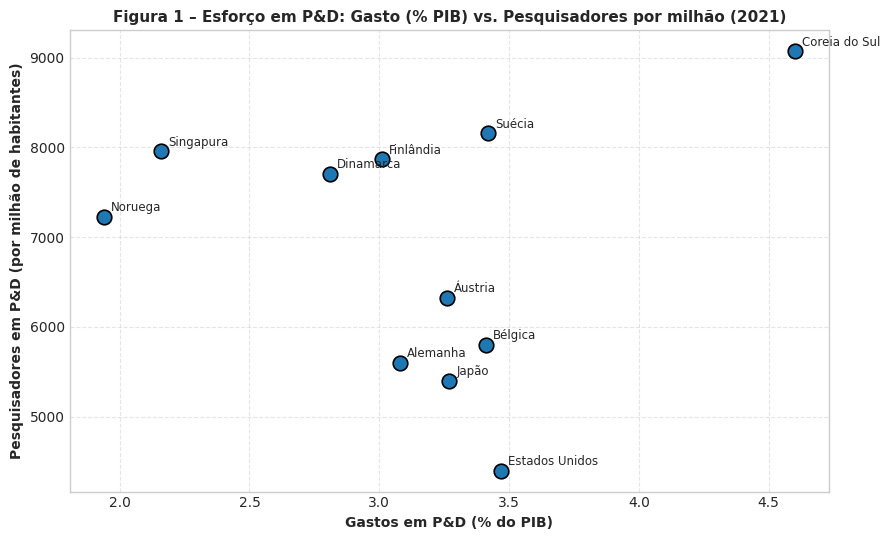

Figura 1 guardada com sucesso!


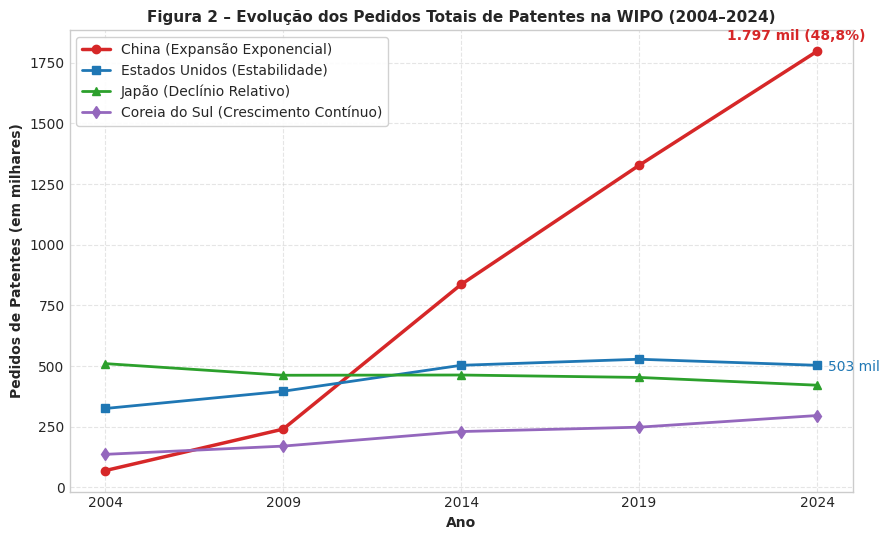

Figura 2 guardada com sucesso!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Configuração de estilo visual acadêmico
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.autolayout'] = True

pasta_graficos = os.path.join(caminho_base, "graficos_fase2")
os.makedirs(pasta_graficos, exist_ok=True)

# -------------------------------------------------------------------------
# FIGURA 1: Esforço em P&D — Gasto (% PIB) vs. Pesquisadores (por milhão)
# -------------------------------------------------------------------------
paises_esforco = ['Coreia do Sul', 'Estados Unidos', 'Suécia', 'Bélgica',
                  'Japão', 'Áustria', 'Alemanha', 'Finlândia', 'Singapura', 'Dinamarca', 'Noruega']

gasto_pib = [4.60, 3.47, 3.42, 3.41, 3.27, 3.26, 3.08, 3.01, 2.16, 2.81, 1.94]
pesquisadores = [9071, 4400, 8160, 5800, 5400, 6323, 5600, 7870, 7956, 7708, 7229]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(gasto_pib, pesquisadores, color='#1f77b4', s=110, edgecolors='black', linewidth=1.2, zorder=3)

for nome, x, y in zip(paises_esforco, gasto_pib, pesquisadores):
    ax.annotate(nome, (x, y), xytext=(5, 4), textcoords='offset points', fontsize=8.5)

ax.set_title('Figura 1 – Esforço em P&D: Gasto (% PIB) vs. Pesquisadores por milhão (2021)')
ax.set_xlabel('Gastos em P&D (% do PIB)')
ax.set_ylabel('Pesquisadores em P&D (por milhão de habitantes)')
ax.grid(True, linestyle='--', alpha=0.5)

caminho_g1 = os.path.join(pasta_graficos, "figura1_esforco_pd.png")
plt.savefig(caminho_g1, dpi=300)
plt.show()
print("Figura 1 guardada com sucesso!")

# -------------------------------------------------------------------------
# FIGURA 2: Reconfiguração Geopolítica — Patentes WIPO (2004–2024)
# -------------------------------------------------------------------------
anos_wipo_str = ['2004', '2009', '2014', '2019', '2024']

patentes_china = [69, 240, 836, 1327, 1797]
patentes_eua = [325, 396, 503, 528, 503]
patentes_japao = [510, 462, 463, 453, 421]
patentes_coreia = [136, 170, 230, 248, 296]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(anos_wipo_str, patentes_china, marker='o', linewidth=2.5, color='#d62728', label='China (Expansão Exponencial)')
ax.plot(anos_wipo_str, patentes_eua, marker='s', linewidth=2.0, color='#1f77b4', label='Estados Unidos (Estabilidade)')
ax.plot(anos_wipo_str, patentes_japao, marker='^', linewidth=2.0, color='#2ca02c', label='Japão (Declínio Relativo)')
ax.plot(anos_wipo_str, patentes_coreia, marker='d', linewidth=2.0, color='#9467bd', label='Coreia do Sul (Crescimento Contínuo)')

ax.annotate('1.797 mil (48,8%)', xy=('2024', 1797), xytext=(-65, 8), textcoords='offset points', fontweight='bold', color='#d62728')
ax.annotate('503 mil', xy=('2024', 503), xytext=(8, -4), textcoords='offset points', color='#1f77b4')

ax.set_title('Figura 2 – Evolução dos Pedidos Totais de Patentes na WIPO (2004–2024)')
ax.set_xlabel('Ano')
ax.set_ylabel('Pedidos de Patentes (em milhares)')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.5)

caminho_g2 = os.path.join(pasta_graficos, "figura2_evolucao_patentes.png")
plt.savefig(caminho_g2, dpi=300)
plt.show()
print("Figura 2 guardada com sucesso!")

# -------------------------------------------------------------------------
# FIGURA 3: O Paradoxo Comercial — Exportações de

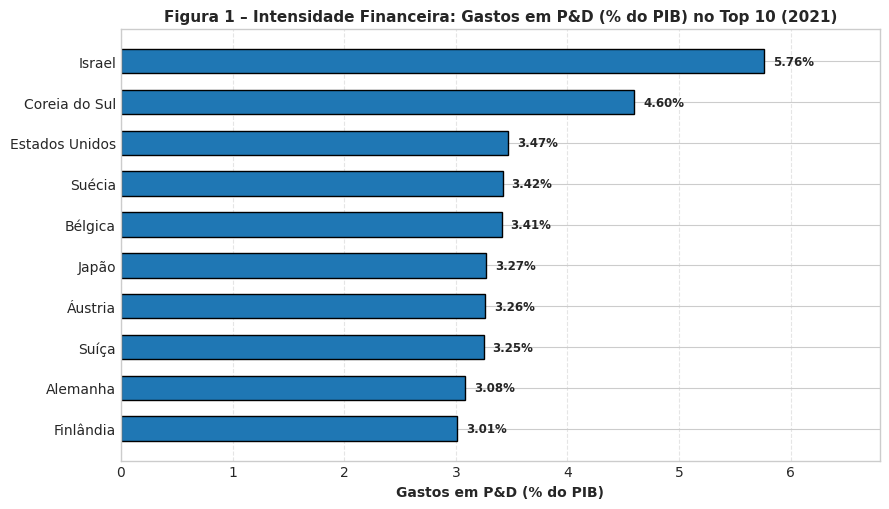

Salvo em: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura1_ranking_gasto_pib.png


In [ ]:
# ==============================================================================
# FIGURA 1: Gastos em P&D (% do PIB) no Ano-Base 2021
# ==============================================================================
import matplotlib.pyplot as plt

paises_gasto = ['Israel', 'Coreia do Sul', 'Estados Unidos', 'Suécia', 'Bélgica',
                'Japão', 'Áustria', 'Suíça', 'Alemanha', 'Finlândia']
valores_gasto = [5.76, 4.60, 3.47, 3.42, 3.41, 3.27, 3.26, 3.25, 3.08, 3.01]

fig, ax = plt.subplots(figsize=(9, 5.2))
barras = ax.barh(paises_gasto, valores_gasto, color='#1f77b4', edgecolor='black', height=0.6)

for barra in barras:
    w = barra.get_width()
    ax.text(w + 0.08, barra.get_y() + barra.get_height()/2, f"{w:.2f}%", va='center', fontsize=8.5, fontweight='bold')

ax.set_title('Figura 1 – Intensidade Financeira: Gastos em P&D (% do PIB) no Top 10 (2021)')
ax.set_xlabel('Gastos em P&D (% do PIB)')
ax.set_xlim(0, 6.8)
ax.invert_yaxis()
ax.grid(True, linestyle='--', alpha=0.5, axis='x')

caminho_g1_novo = os.path.join(pasta_graficos, "figura1_ranking_gasto_pib.png")
plt.savefig(caminho_g1_novo, dpi=300)
plt.show()
print(f"Salvo em: {caminho_g1_novo}")

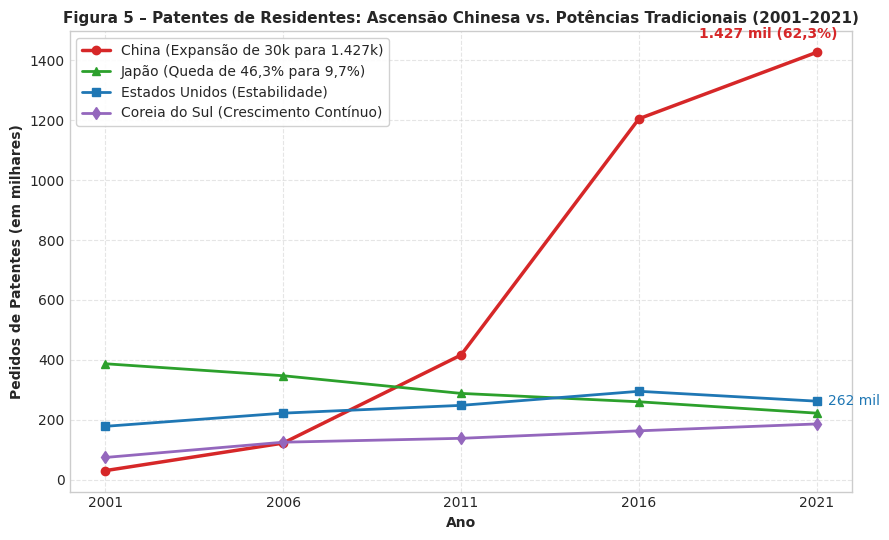

Salvo em: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura5_patentes_bm.png


In [ ]:
# ==============================================================================
# FIGURA 5: Evolução das Patentes de Residentes (Banco Mundial 2001–2021)
# ==============================================================================
anos_bm_str = ['2001', '2006', '2011', '2016', '2021']

# Dados em milhares
pat_bm_china = [30, 122, 416, 1205, 1427]
pat_bm_japao = [387, 347, 288, 260, 222]
pat_bm_eua = [178, 222, 248, 295, 262]
pat_bm_coreia = [74, 125, 138, 163, 186]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(anos_bm_str, pat_bm_china, marker='o', linewidth=2.5, color='#d62728', label='China (Expansão de 30k para 1.427k)')
ax.plot(anos_bm_str, pat_bm_japao, marker='^', linewidth=2.0, color='#2ca02c', label='Japão (Queda de 46,3% para 9,7%)')
ax.plot(anos_bm_str, pat_bm_eua, marker='s', linewidth=2.0, color='#1f77b4', label='Estados Unidos (Estabilidade)')
ax.plot(anos_bm_str, pat_bm_coreia, marker='d', linewidth=2.0, color='#9467bd', label='Coreia do Sul (Crescimento Contínuo)')

ax.annotate('1.427 mil (62,3%)', xy=('2021', 1427), xytext=(-85, 10), textcoords='offset points', fontweight='bold', color='#d62728')
ax.annotate('262 mil', xy=('2021', 262), xytext=(8, -3), textcoords='offset points', color='#1f77b4')

ax.set_title('Figura 5 – Patentes de Residentes: Ascensão Chinesa vs. Potências Tradicionais (2001–2021)')
ax.set_xlabel('Ano')
ax.set_ylabel('Pedidos de Patentes (em milhares)')
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.5)

caminho_g5_novo = os.path.join(pasta_graficos, "figura5_patentes_bm.png")
plt.savefig(caminho_g5_novo, dpi=300)
plt.show()
print(f"Salvo em: {caminho_g5_novo}")

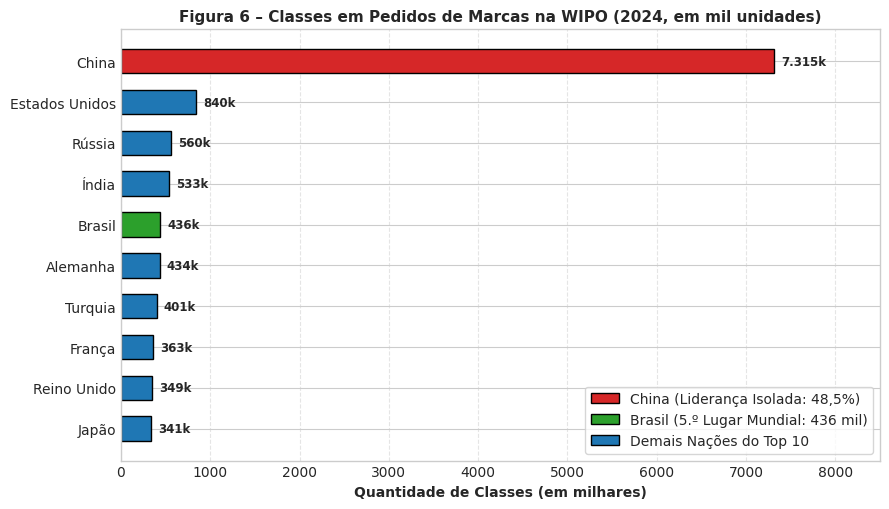

Salvo em: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura6_marcas_wipo.png


In [ ]:
# ==============================================================================
# FIGURA 6: Classes em Pedidos de Marcas na WIPO (2024)
# ==============================================================================
paises_marcas = ['China', 'Estados Unidos', 'Rússia', 'Índia', 'Brasil',
                 'Alemanha', 'Turquia', 'França', 'Reino Unido', 'Japão']
qtdes_marcas = [7315, 840, 560, 533, 436, 434, 401, 363, 349, 341] # em milhares

cores_marcas = ['#d62728' if p == 'China' else ('#2ca02c' if p == 'Brasil' else '#1f77b4') for p in paises_marcas]

fig, ax = plt.subplots(figsize=(9, 5.2))
barras = ax.barh(paises_marcas, qtdes_marcas, color=cores_marcas, edgecolor='black', height=0.6)

for barra in barras:
    w = barra.get_width()
    ax.text(w + 80, barra.get_y() + barra.get_height()/2, f"{int(w):,}k".replace(",", "."), va='center', fontsize=8.5, fontweight='bold')

ax.set_title('Figura 6 – Classes em Pedidos de Marcas na WIPO (2024, em mil unidades)')
ax.set_xlabel('Quantidade de Classes (em milhares)')
ax.set_xlim(0, 8500)
ax.invert_yaxis()
ax.grid(True, linestyle='--', alpha=0.5, axis='x')

from matplotlib.patches import Patch
leg_elem = [
    Patch(facecolor='#d62728', edgecolor='black', label='China (Liderança Isolada: 48,5%)'),
    Patch(facecolor='#2ca02c', edgecolor='black', label='Brasil (5.º Lugar Mundial: 436 mil)'),
    Patch(facecolor='#1f77b4', edgecolor='black', label='Demais Nações do Top 10')
]
ax.legend(handles=leg_elem, loc='lower right', frameon=True)

caminho_g6_novo = os.path.join(pasta_graficos, "figura6_marcas_wipo.png")
plt.savefig(caminho_g6_novo, dpi=300)
plt.show()
print(f"Salvo em: {caminho_g6_novo}")

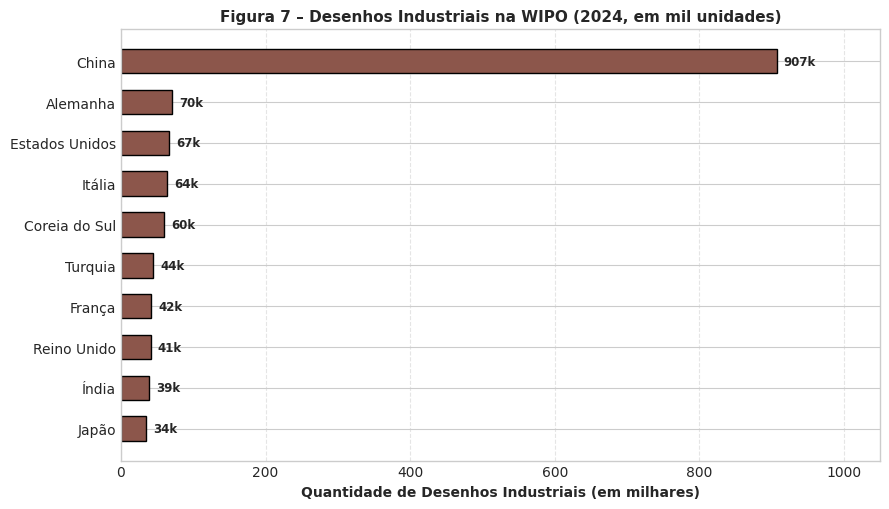

Salvo em: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura7_desenhos_wipo.png


In [ ]:
# ==============================================================================
# FIGURA 7: Desenhos Industriais em Pedidos na WIPO (2024)
# ==============================================================================
paises_desenhos = ['China', 'Alemanha', 'Estados Unidos', 'Itália', 'Coreia do Sul',
                   'Turquia', 'França', 'Reino Unido', 'Índia', 'Japão']
qtdes_desenhos = [907, 70, 67, 64, 60, 44, 42, 41, 39, 34] # em milhares

fig, ax = plt.subplots(figsize=(9, 5.2))
barras = ax.barh(paises_desenhos, qtdes_desenhos, color='#8c564b', edgecolor='black', height=0.6)

for barra in barras:
    w = barra.get_width()
    ax.text(w + 10, barra.get_y() + barra.get_height()/2, f"{int(w)}k", va='center', fontsize=8.5, fontweight='bold')

ax.set_title('Figura 7 – Desenhos Industriais na WIPO (2024, em mil unidades)')
ax.set_xlabel('Quantidade de Desenhos Industriais (em milhares)')
ax.set_xlim(0, 1050)
ax.invert_yaxis()
ax.grid(True, linestyle='--', alpha=0.5, axis='x')

caminho_g7_novo = os.path.join(pasta_graficos, "figura7_desenhos_wipo.png")
plt.savefig(caminho_g7_novo, dpi=300)
plt.show()
print(f"Salvo em: {caminho_g7_novo}")

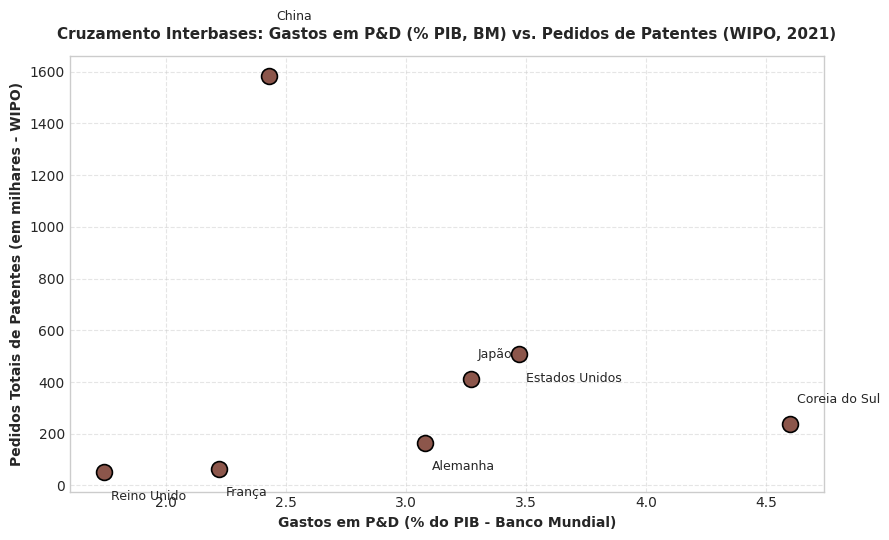

Salvo: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura_interbases_pd_vs_patentes.png


In [ ]:
# ==============================================================================
# FIGURA EXTRA 1: CRUZAMENTO BANCO MUNDIAL (P&D) x WIPO (PATENTES)
# ==============================================================================
import matplotlib.pyplot as plt
import os

paises_cruzamento1 = ['Coreia do Sul', 'Estados Unidos', 'Alemanha', 'Japão', 'China', 'Reino Unido', 'França']
gasto_pib_2021 = [4.60, 3.47, 3.08, 3.27, 2.43, 1.74, 2.22] # Banco Mundial (2021)
patentes_wipo_2021 = [238, 509, 166, 413, 1585, 53, 65]    # WIPO em milhares (2021)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(gasto_pib_2021, patentes_wipo_2021, color='#8c564b', s=130, edgecolors='black', linewidth=1.2, zorder=3)

for nome, x, y in zip(paises_cruzamento1, gasto_pib_2021, patentes_wipo_2021):
    offset_y = 40 if nome == 'China' else (15 if nome in ['Japão', 'Coreia do Sul'] else -20)
    ax.annotate(nome, (x, y), xytext=(5, offset_y), textcoords='offset points', fontsize=9, fontweight='medium')

ax.set_title('Cruzamento Interbases: Gastos em P&D (% PIB, BM) vs. Pedidos de Patentes (WIPO, 2021)', pad=12)
ax.set_xlabel('Gastos em P&D (% do PIB - Banco Mundial)')
ax.set_ylabel('Pedidos Totais de Patentes (em milhares - WIPO)')
ax.grid(True, linestyle='--', alpha=0.5)

caminho_inter1 = os.path.join(pasta_graficos, "figura_interbases_pd_vs_patentes.png")
plt.savefig(caminho_inter1, dpi=300)
plt.show()
print(f"Salvo: {caminho_inter1}")


# ==============================================================================
# FIGURA EXTRA 2: CRUZAMENTO BANCO MUNDIAL (PESQUISADORES) x WIPO (MARCAS)
# ==============================================================================
paises_cruzamento2 = ['Brasil', 'Coreia do Sul', 'Alemanha', 'Japão', 'Reino Unido', 'França', 'Rússia']
pesquisadores_milhao = [885, 9071, 5600, 5400, 4600, 4900, 2700] # Banco

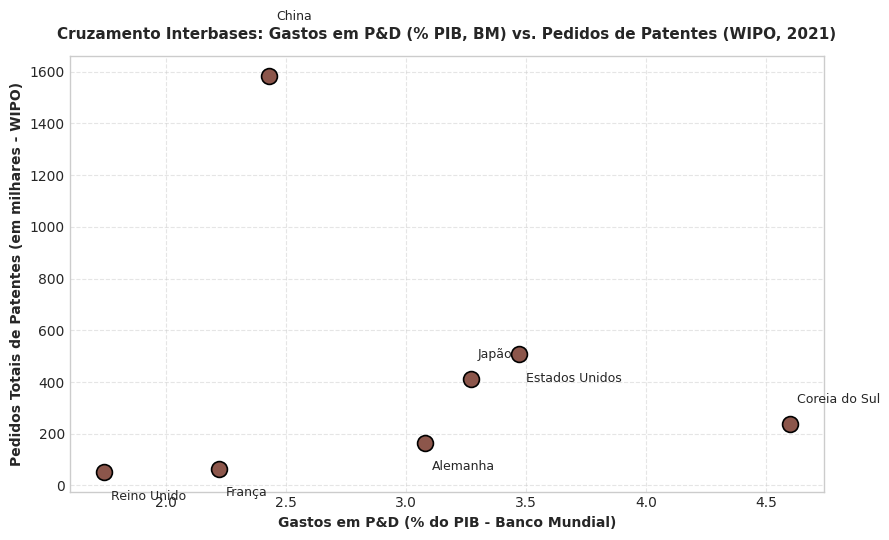

Salvo: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura_interbases_pd_vs_patentes.png


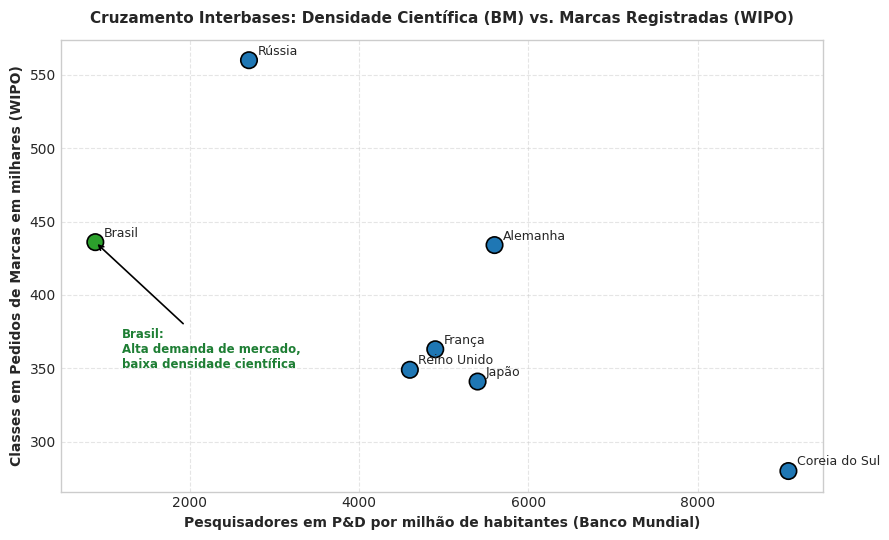

Salvo: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura_interbases_pesquisadores_vs_marcas.png


In [ ]:
# ==============================================================================
# FIGURA EXTRA 1: CRUZAMENTO BANCO MUNDIAL (P&D) x WIPO (PATENTES)
# ==============================================================================
import matplotlib.pyplot as plt
import os

paises_cruzamento1 = ['Coreia do Sul', 'Estados Unidos', 'Alemanha', 'Japão', 'China', 'Reino Unido', 'França']
gasto_pib_2021 = [4.60, 3.47, 3.08, 3.27, 2.43, 1.74, 2.22] # Banco Mundial (2021)
patentes_wipo_2021 = [238, 509, 166, 413, 1585, 53, 65]    # WIPO em milhares (2021)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(gasto_pib_2021, patentes_wipo_2021, color='#8c564b', s=130, edgecolors='black', linewidth=1.2, zorder=3)

for nome, x, y in zip(paises_cruzamento1, gasto_pib_2021, patentes_wipo_2021):
    offset_y = 40 if nome == 'China' else (15 if nome in ['Japão', 'Coreia do Sul'] else -20)
    ax.annotate(nome, (x, y), xytext=(5, offset_y), textcoords='offset points', fontsize=9, fontweight='medium')

ax.set_title('Cruzamento Interbases: Gastos em P&D (% PIB, BM) vs. Pedidos de Patentes (WIPO, 2021)', pad=12)
ax.set_xlabel('Gastos em P&D (% do PIB - Banco Mundial)')
ax.set_ylabel('Pedidos Totais de Patentes (em milhares - WIPO)')
ax.grid(True, linestyle='--', alpha=0.5)

caminho_inter1 = os.path.join(pasta_graficos, "figura_interbases_pd_vs_patentes.png")
plt.savefig(caminho_inter1, dpi=300)
plt.show()
print(f"Salvo: {caminho_inter1}")


# ==============================================================================
# FIGURA EXTRA 2: CRUZAMENTO BANCO MUNDIAL (PESQUISADORES) x WIPO (MARCAS)
# ==============================================================================
paises_cruzamento2 = ['Brasil', 'Coreia do Sul', 'Alemanha', 'Japão', 'Reino Unido', 'França', 'Rússia']
pesquisadores_milhao = [885, 9071, 5600, 5400, 4600, 4900, 2700] # Banco Mundial
marcas_wipo_milhares = [436, 280, 434, 341, 349, 363, 560]      # WIPO 2024 / recentes

fig, ax = plt.subplots(figsize=(9, 5.5))
cores = ['#2ca02c' if p == 'Brasil' else '#1f77b4' for p in paises_cruzamento2]
ax.scatter(pesquisadores_milhao, marcas_wipo_milhares, color=cores, s=140, edgecolors='black', linewidth=1.2, zorder=3)

for nome, x, y in zip(paises_cruzamento2, pesquisadores_milhao, marcas_wipo_milhares):
    ax.annotate(nome, (x, y), xytext=(6, 4), textcoords='offset points', fontsize=9, fontweight='medium')

ax.set_title('Cruzamento Interbases: Densidade Científica (BM) vs. Marcas Registradas (WIPO)', pad=12)
ax.set_xlabel('Pesquisadores em P&D por milhão de habitantes (Banco Mundial)')
ax.set_ylabel('Classes em Pedidos de Marcas em milhares (WIPO)')
ax.grid(True, linestyle='--', alpha=0.5)

# Destaque para o Brasil
ax.annotate('Brasil:\nAlta demanda de mercado,\nbaixa densidade científica',
            xy=(885, 436), xytext=(1200, 350),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
            fontsize=8.5, fontweight='bold', color='#1e7e34')

caminho_inter2 = os.path.join(pasta_graficos, "figura_interbases_pesquisadores_vs_marcas.png")
plt.savefig(caminho_inter2, dpi=300)
plt.show()
print(f"Salvo: {caminho_inter2}")

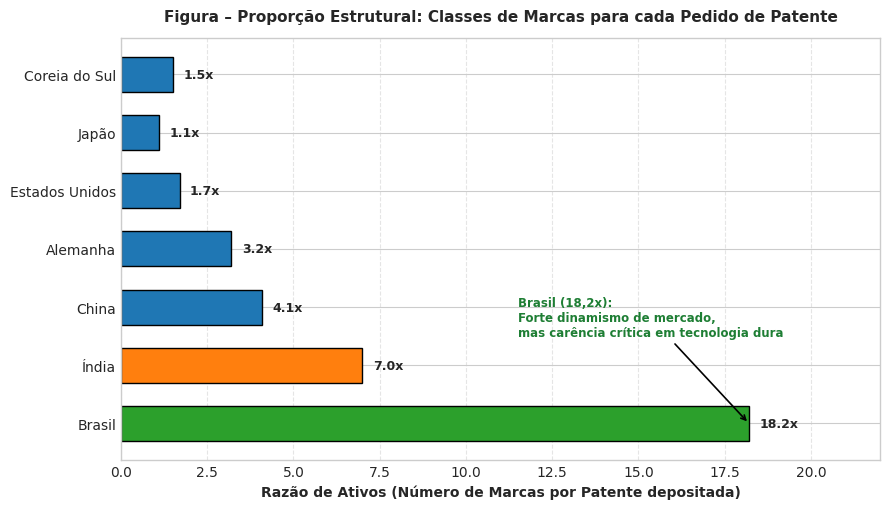

Salvo em: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura_razao_marcas_patentes_brasil.png


In [ ]:
# ==============================================================================
# FIGURA: A RAZÃO ENTRE ATIVOS DE MERCADO (MARCAS) E TECNOLOGIA (PATENTES)
# ==============================================================================
import matplotlib.pyplot as plt
import os

paises_razao = ['Coreia do Sul', 'Japão', 'Estados Unidos', 'Alemanha', 'China', 'Índia', 'Brasil']

# Relação aproximada: Número de classes de marcas registradas por pedido de patente (2021-2024)
# Coreia: ~1,5 marcas/patente | Japão: ~1,1 | EUA: ~1,7 | Alemanha: ~3,2 | China: ~4,0 | Índia: ~7,0 | Brasil: ~18,5
razao_marcas_patente = [1.5, 1.1, 1.7, 3.2, 4.1, 7.0, 18.2]

cores = ['#2ca02c' if p == 'Brasil' else ('#1f77b4' if r < 5 else '#ff7f0e') for p, r in zip(paises_razao, razao_marcas_patente)]

fig, ax = plt.subplots(figsize=(9, 5.2))
barras = ax.barh(paises_razao, razao_marcas_patente, color=cores, edgecolor='black', height=0.6)

for barra in barras:
    w = barra.get_width()
    ax.text(w + 0.3, barra.get_y() + barra.get_height()/2, f"{w:.1f}x", va='center', fontsize=9, fontweight='bold')

ax.set_title('Figura – Proporção Estrutural: Classes de Marcas para cada Pedido de Patente', pad=12)
ax.set_xlabel('Razão de Ativos (Número de Marcas por Patente depositada)')
ax.set_xlim(0, 22)
ax.invert_yaxis()
ax.grid(True, linestyle='--', alpha=0.5, axis='x')

# Anotação analítica destacando o Brasil
ax.annotate('Brasil (18,2x):\nForte dinamismo de mercado,\nmas carência crítica em tecnologia dura',
            xy=(18.2, 6), xytext=(11.5, 4.5),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
            fontsize=8.5, fontweight='bold', color='#1e7e34')

caminho_razao = os.path.join(pasta_graficos, "figura_razao_marcas_patentes_brasil.png")
plt.savefig(caminho_razao, dpi=300)
plt.show()
print(f"Salvo em: {caminho_razao}")

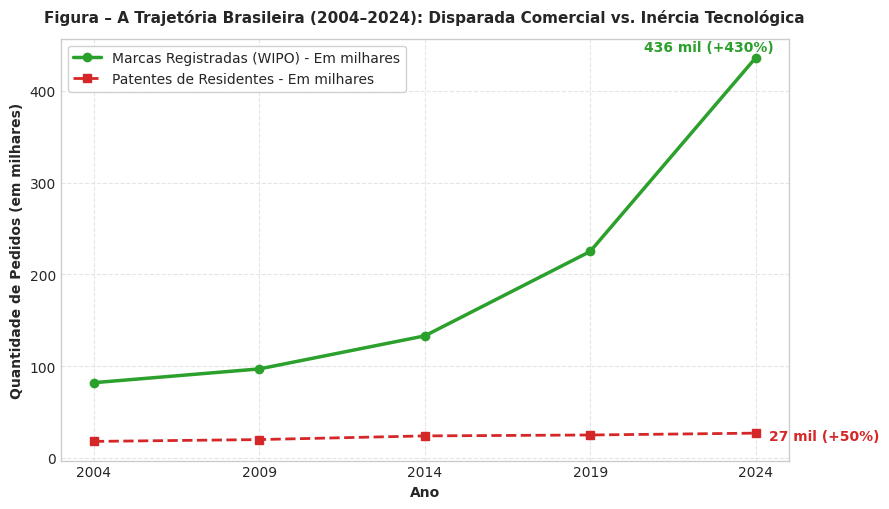

Salvo em: /content/drive/MyDrive/dados_brutos/graficos_fase2/figura_trajetoria_brasil_marcas_patentes.png


In [ ]:
# ==============================================================================
# FIGURA: TRAJETÓRIA COMPARADA DO BRASIL (MARCAS vs. PATENTES NA WIPO/BM)
# ==============================================================================
anos_brasil = ['2004', '2009', '2014', '2019', '2024']

# Séries temporais em milhares de pedidos
marcas_brasil = [82, 97, 133, 225, 436]      # Crescimento acelerado (de 82k para 436k)
patentes_brasil = [18, 20, 24, 25, 27]       # Quase estagnado no tempo

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(anos_brasil, marcas_brasil, marker='o', linewidth=2.5, color='#2ca02c', label='Marcas Registradas (WIPO) - Em milhares')
ax.plot(anos_brasil, patentes_brasil, marker='s', linewidth=2.0, color='#d62728', linestyle='--', label='Patentes de Residentes - Em milhares')

ax.annotate('436 mil (+430%)', xy=('2024', 436), xytext=(-80, 5), textcoords='offset points', fontweight='bold', color='#2ca02c')
ax.annotate('27 mil (+50%)', xy=('2024', 27), xytext=(10, -5), textcoords='offset points', fontweight='bold', color='#d62728')

ax.set_title('Figura – A Trajetória Brasileira (2004–2024): Disparada Comercial vs. Inércia Tecnológica', pad=12)
ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de Pedidos (em milhares)')
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')
ax.grid(True, linestyle='--', alpha=0.5)

caminho_traj_br = os.path.join(pasta_graficos, "figura_trajetoria_brasil_marcas_patentes.png")
plt.savefig(caminho_traj_br, dpi=300)
plt.show()
print(f"Salvo em: {caminho_traj_br}")